## Make timeseries of SST, Chl within each biome, for each season
### Model and Observations

In [1]:
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import pop_tools 
from statistics import mean
from matplotlib import style
import matplotlib
from scipy import stats

### Get CESM model grid info

In [2]:
### First, get the pop grid information, so we have lon, lat
ds_grid = pop_tools.get_grid('POP_gx1v7')
lats = ds_grid.TLAT
lons = ds_grid.TLONG
area_model = ds_grid.TAREA

### Read in biomes 

In [3]:
### Read in biomes for model
ds_biome_model = xr.open_dataset('../biomes/CESM2_biomes.nc')

In [4]:
### Read in biomes for obs
ds_biome_obs = xr.open_dataset('../biomes/Obs_biomes.nc')

### Read in CESM SST and Chl

In [5]:
output_dir = '/glade/derecho/scratch/kristenk/INDEX_BGC_work'

ds_DJF_model = xr.open_dataset(output_dir + '/dsDJF_cesm_2003to2021.nc')
ds_MAM_model = xr.open_dataset(output_dir + '/dsMAM_cesm_2003to2021.nc')
ds_JJA_model = xr.open_dataset(output_dir + '/dsJJA_cesm_2003to2021.nc')
ds_SON_model = xr.open_dataset(output_dir + '/dsSON_cesm_2003to2021.nc')

### Read in obs SST and Chl

In [6]:
ds_DJF_obs = xr.open_dataset(output_dir + '/dsDJF_obs_2003to2021.nc')
ds_MAM_obs = xr.open_dataset(output_dir + '/dsMAM_obs_2003to2021.nc')
ds_JJA_obs = xr.open_dataset(output_dir + '/dsJJA_obs_2003to2021.nc')
ds_SON_obs = xr.open_dataset(output_dir + '/dsSON_obs_2003to2021.nc')

### Create a dictionary with biome names, numbers

In [7]:
biome_num_dict = {'NH_ICE':1,
                  'NPac_SPSS':2,
                  'NAtl_SPSS':3,
                  'NH_STSS':4,
                  'NH_STPS':5,
                  'IND_STPS':6,
                  'WPac_EQ':7,
                  'EPac_EQ':8,
                  'Atl_EQ':9,
                  'SH_ICE':10,
                  'SH_SPSS':11,
                  'SH_STSS':12,
                  'SH_STPS':13}



In [8]:
biome_num_dict['NH_ICE']

1

In [9]:
biome_names = ['NH_ICE','NPac_SPSS','NAtl_SPSS',
          'NH_STSS','NH_STPS','IND_STPS','WPac_EQ',
          'EPac_EQ','Atl_EQ','SH_ICE','SH_SPSS','SH_STSS',
          'SH_STPS']

### Calculate area for making area-weighted averages

In [10]:
area_obs = xr.DataArray(np.zeros([180,360]), dims=('lat','lon'))

j=0

for lat in ds_biome_obs.lat.values:

    pi     =    3.14159265359
    radius = 6378.137
    
    deg2rad = pi / 180.0
    
    resolution_lat =1. #res in degrees
    resolution_lon =1. #res in degrees
    
    elevation = deg2rad * (lat + (resolution_lat / 2.0))
    
    deltalat = deg2rad * resolution_lon
    deltalon = deg2rad * resolution_lat
    
    area_obs[j,:] = (2.0*radius**2*deltalon*np.cos(elevation)*np.sin((deltalat/2.0)))
    
    j = j + 1

### now make dictionaries that will contain timeseries for each biome

In [11]:
obs_biome_dict_DJF = {}
obs_biome_dict_MAM = {}
obs_biome_dict_JJA = {}
obs_biome_dict_SON = {}

model_biome_dict_DJF = {}
model_biome_dict_MAM = {}
model_biome_dict_JJA = {}
model_biome_dict_SON = {}

In [12]:
obs_vars = ['Chl', 'ice', 'SST']
mod_vars = ['Chl', 'IFRAC', 'TEMP']

In [13]:
for biome in biome_names:
    print(biome)

    #### first do obs
    masked_area = area_obs.where(ds_biome_obs.biome==biome_num_dict[biome])
    
    ds_DJF = xr.Dataset() #initialize empty dataset for this biome/season
    ds_MAM = xr.Dataset() #initialize empty dataset for this biome/season
    ds_JJA = xr.Dataset() #initialize empty dataset for this biome/season
    ds_SON = xr.Dataset() #initialize empty dataset for this biome/season
    
    for var in obs_vars:
        #print(var)
        
        ### DJF
        masked_var = ds_DJF_obs[var].where(ds_biome_obs.biome==biome_num_dict[biome])
        weighted_mean = (masked_var * masked_area).sum(dim=('lon','lat')) / masked_area.sum(dim=('lon','lat'))
        ds_DJF[var] = weighted_mean
    
        ### MAM
        masked_var = ds_MAM_obs[var].where(ds_biome_obs.biome==biome_num_dict[biome])
        weighted_mean = (masked_var * masked_area).sum(dim=('lon','lat')) / masked_area.sum(dim=('lon','lat'))
        ds_MAM[var] = weighted_mean

        ### JJA
        masked_var = ds_JJA_obs[var].where(ds_biome_obs.biome==biome_num_dict[biome])
        weighted_mean = (masked_var * masked_area).sum(dim=('lon','lat')) / masked_area.sum(dim=('lon','lat'))
        ds_JJA[var] = weighted_mean

        ### SON
        masked_var = ds_SON_obs[var].where(ds_biome_obs.biome==biome_num_dict[biome])
        weighted_mean = (masked_var * masked_area).sum(dim=('lon','lat')) / masked_area.sum(dim=('lon','lat'))
        ds_SON[var] = weighted_mean
        
    obs_biome_dict_DJF[biome] = ds_DJF
    obs_biome_dict_MAM[biome] = ds_MAM
    obs_biome_dict_JJA[biome] = ds_JJA
    obs_biome_dict_SON[biome] = ds_SON

    ##### now do model
    masked_area = area_model.where(ds_biome_model.biome==biome_num_dict[biome])
    
    ds_DJF = xr.Dataset() #initialize empty dataset for this biome/season
    ds_MAM = xr.Dataset() #initialize empty dataset for this biome/season
    ds_JJA = xr.Dataset() #initialize empty dataset for this biome/season
    ds_SON = xr.Dataset() #initialize empty dataset for this biome/season
    for var in mod_vars:
        #print(var)
        
        ### DJF
        masked_var = ds_DJF_model[var].where(ds_biome_model.biome==biome_num_dict[biome])
        weighted_mean = (masked_var * masked_area).sum(dim=('nlon','nlat')) / masked_area.sum(dim=('nlon','nlat'))
        ds_DJF[var] = weighted_mean

        ### MAM
        masked_var = ds_MAM_model[var].where(ds_biome_model.biome==biome_num_dict[biome])
        weighted_mean = (masked_var * masked_area).sum(dim=('nlon','nlat')) / masked_area.sum(dim=('nlon','nlat'))
        ds_MAM[var] = weighted_mean

        ### JJA
        masked_var = ds_JJA_model[var].where(ds_biome_model.biome==biome_num_dict[biome])
        weighted_mean = (masked_var * masked_area).sum(dim=('nlon','nlat')) / masked_area.sum(dim=('nlon','nlat'))
        ds_JJA[var] = weighted_mean

        ### SON
        masked_var = ds_SON_model[var].where(ds_biome_model.biome==biome_num_dict[biome])
        weighted_mean = (masked_var * masked_area).sum(dim=('nlon','nlat')) / masked_area.sum(dim=('nlon','nlat'))
        ds_SON[var] = weighted_mean
        
    model_biome_dict_DJF[biome] = ds_DJF
    model_biome_dict_MAM[biome] = ds_MAM
    model_biome_dict_JJA[biome] = ds_JJA
    model_biome_dict_SON[biome] = ds_SON

NH_ICE
NPac_SPSS
NAtl_SPSS
NH_STSS
NH_STPS
IND_STPS
WPac_EQ
EPac_EQ
Atl_EQ
SH_ICE
SH_SPSS
SH_STSS
SH_STPS


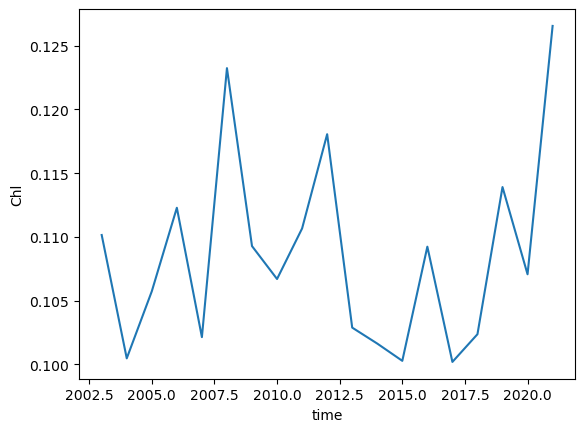

In [14]:
model_biome_dict_DJF['WPac_EQ'].Chl.plot()

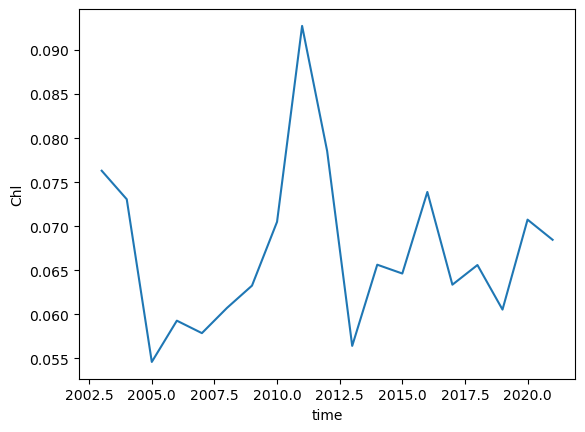

In [15]:
obs_biome_dict_DJF['WPac_EQ'].Chl.plot()

### Make a colormap for the figures

In [16]:
from matplotlib.colors import ListedColormap

In [17]:
unique_cats, cat_codes = np.unique(biome_names, return_inverse=True)
num_cats = len(unique_cats)

# 2. Extract a discrete N-bin version of a qualitative colormap
cmap_biome = plt.get_cmap('tab20', num_cats)

# cmap_biome = matplotlib.colors.LinearSegmentedColormap.from_list('biomes', colors, N=13)

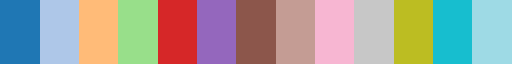

In [18]:
cmap_biome

In [19]:
num_cats

13

### DJF SST vs. Chl (obs on left, model on right) for each biome

1


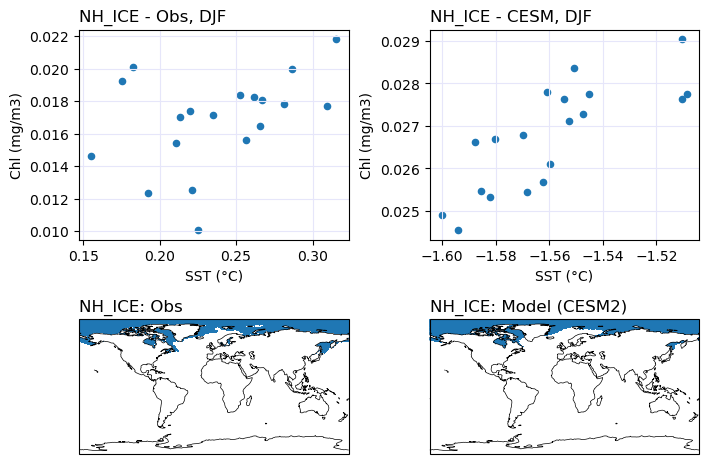

----------------------------------------------------------------------------------------------
2


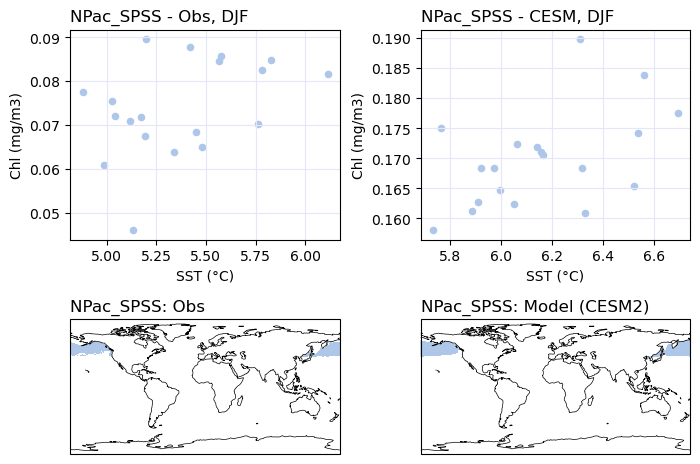

----------------------------------------------------------------------------------------------
3


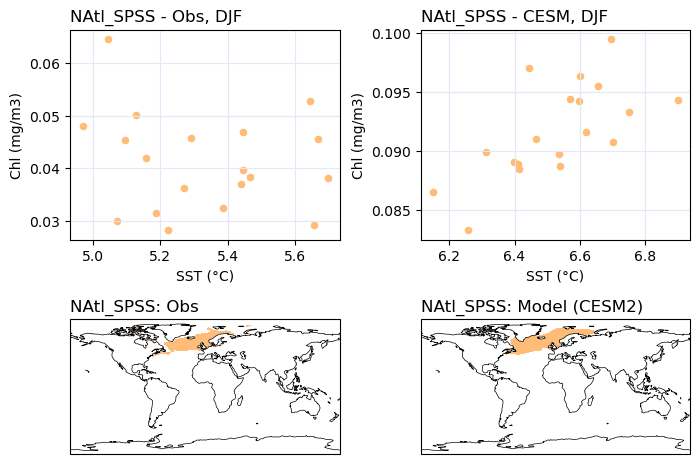

----------------------------------------------------------------------------------------------
4


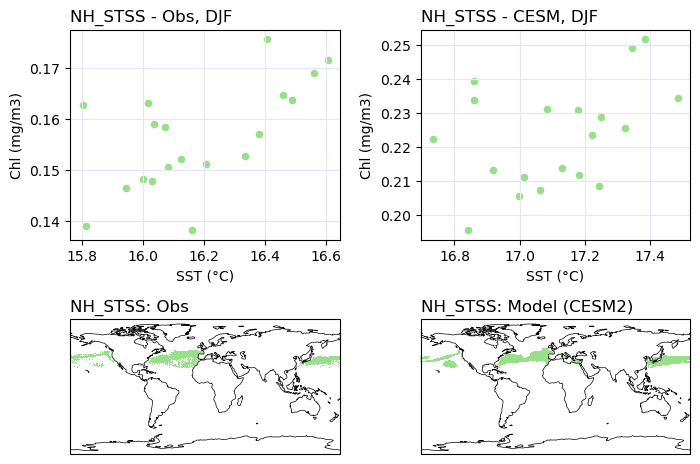

----------------------------------------------------------------------------------------------
5


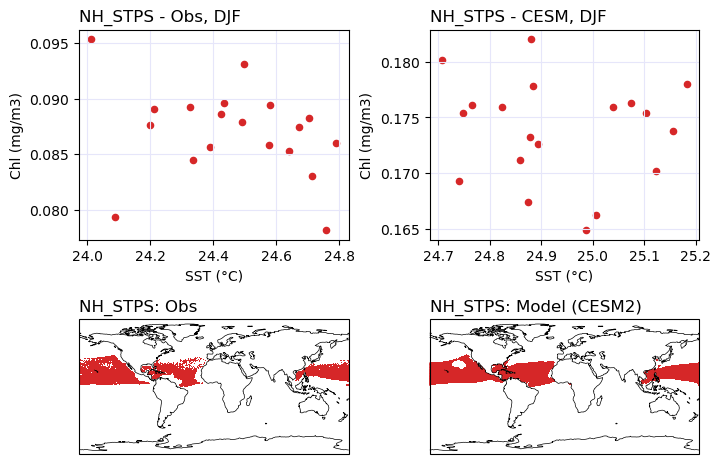

----------------------------------------------------------------------------------------------
6


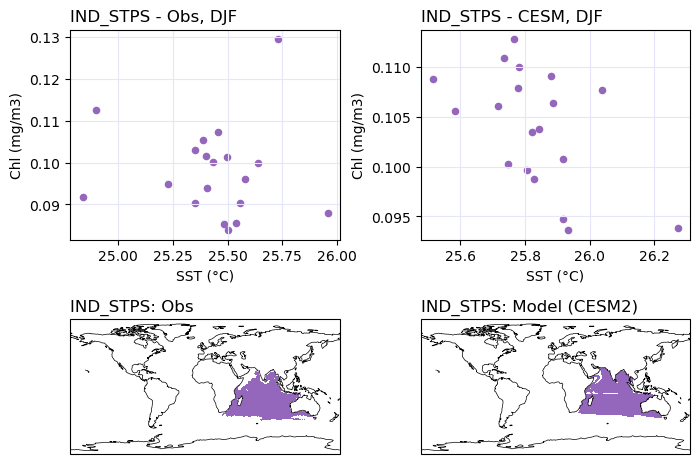

----------------------------------------------------------------------------------------------
7


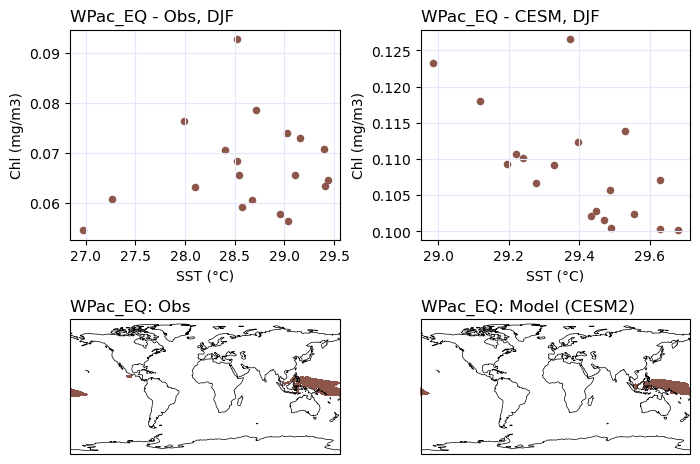

----------------------------------------------------------------------------------------------
8


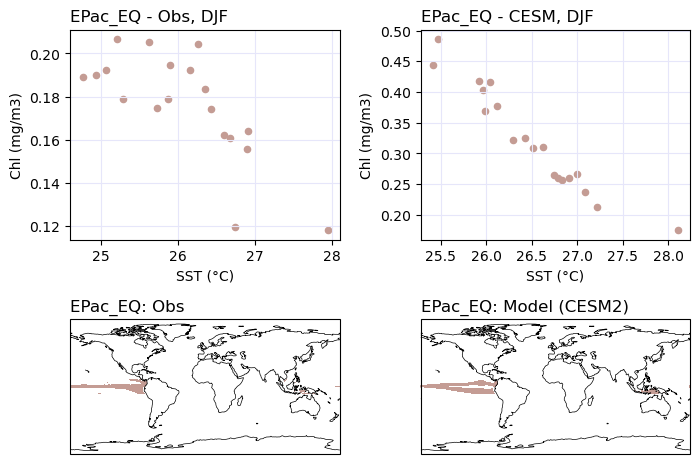

----------------------------------------------------------------------------------------------
9


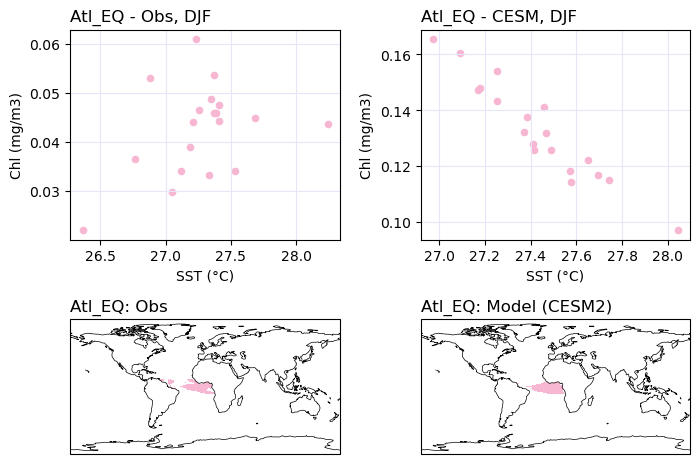

----------------------------------------------------------------------------------------------
10


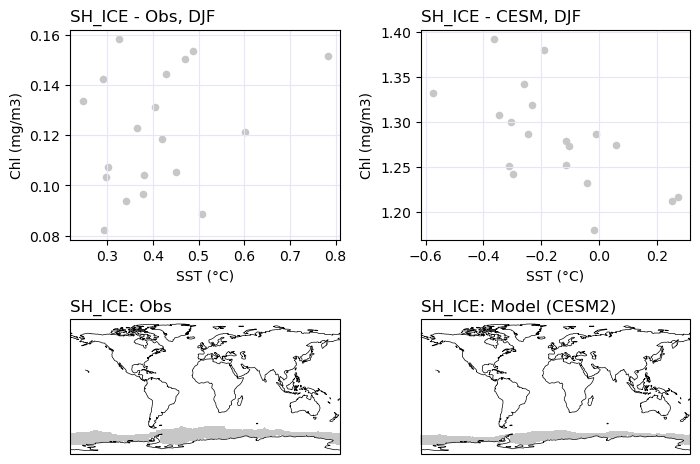

----------------------------------------------------------------------------------------------
11


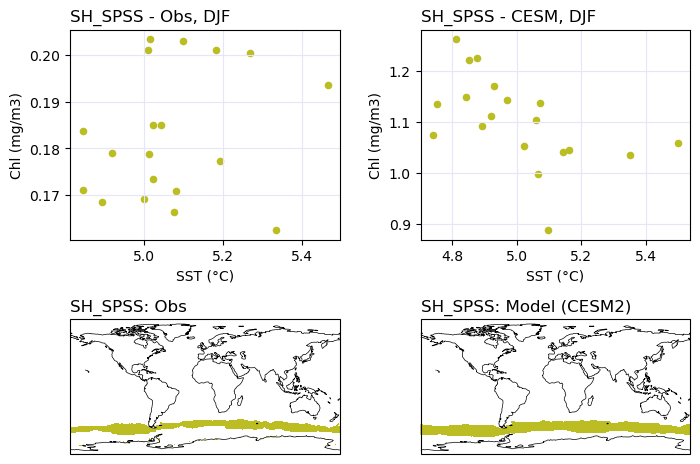

----------------------------------------------------------------------------------------------
12


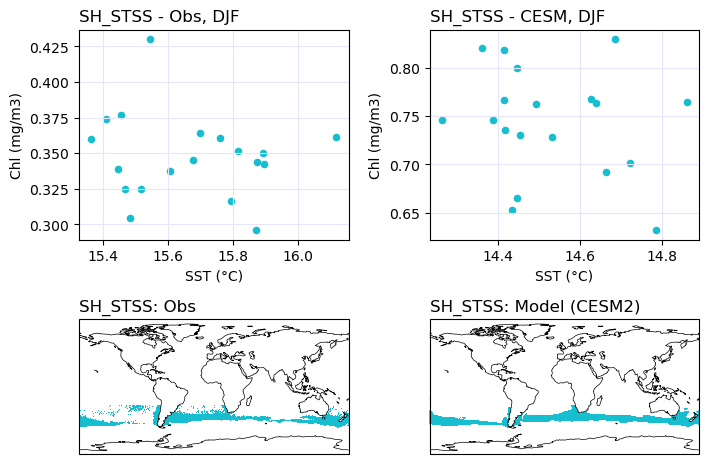

----------------------------------------------------------------------------------------------
13


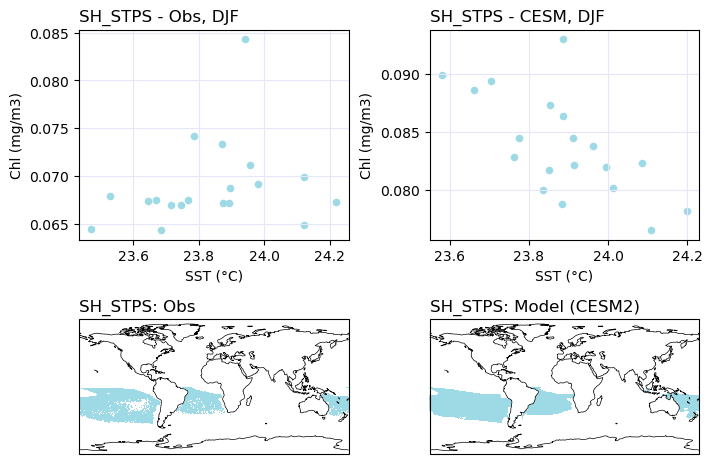

----------------------------------------------------------------------------------------------


In [34]:
for biome in biome_names:

    print(biome_num_dict[biome])
    fig = plt.figure(figsize=(8,6))

    ax = fig.add_subplot(2,2,1)
    ax.set_title(biome + ' - Obs, DJF', loc='left')
    xvals = obs_biome_dict_DJF[biome].SST
    yvals = obs_biome_dict_DJF[biome].Chl
    rgba_color = cmap_biome(biome_num_dict[biome]/14)
    sc = ax.scatter(xvals, yvals, color=rgba_color, s=20)
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender');
    ax.set_xlabel('SST (°C)')
    ax.set_ylabel('Chl (mg/m3)')
    #ax.set_ylim(0,3)
    
    ax = fig.add_subplot(2,2,2)
    ax.set_title(biome + ' - CESM, DJF', loc='left')
    xvals = model_biome_dict_DJF[biome].TEMP
    yvals = model_biome_dict_DJF[biome].Chl
    rgba_color = cmap_biome(biome_num_dict[biome]/14)
    sc = ax.scatter(xvals, yvals, color=rgba_color, s=20)
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender');
    ax.set_xlabel('SST (°C)')
    ax.set_ylabel('Chl (mg/m3)');
    #ax.set_ylim(0,3);


    ax = fig.add_subplot(2,2,3, projection=ccrs.PlateCarree())
    ax.coastlines('110m',linewidth=0.5)
    ax.set_title(biome + ': Obs', fontsize=12, loc='left')
    pc1=ax.pcolormesh(ds_biome_obs.lon, ds_biome_obs.lat, (ds_biome_obs.biome-0.5).where(ds_biome_obs.biome==biome_num_dict[biome]), cmap=cmap_biome,vmin=0,vmax=13,
                      transform=ccrs.PlateCarree())
    #pci=ax.contourf(lons, lats, all_biomes.where(all_biomes==0),levels=[0,0.99],transform=ccrs.PlateCarree(),hatches=['//'],colors='none')
    
    ax = fig.add_subplot(2,2,4, projection=ccrs.PlateCarree())
    ax.set_extent([-180,180,-90, 90], ccrs.PlateCarree())
    ax.coastlines('110m',linewidth=0.5)
    ax.set_title(biome + ': Model (CESM2)', fontsize=12, loc='left')
    pc1=ax.pcolormesh(lons, lats, (ds_biome_model.biome-0.5).where(ds_biome_model.biome==biome_num_dict[biome]), cmap=cmap_biome,vmin=0,vmax=13,
                      transform=ccrs.PlateCarree())
    
    fig.subplots_adjust(wspace=0.3)
    
    plt.show()
    print('----------------------------------------------------------------------------------------------')

### MAM SST vs. Chl (obs on left, model on right) for each biome

1


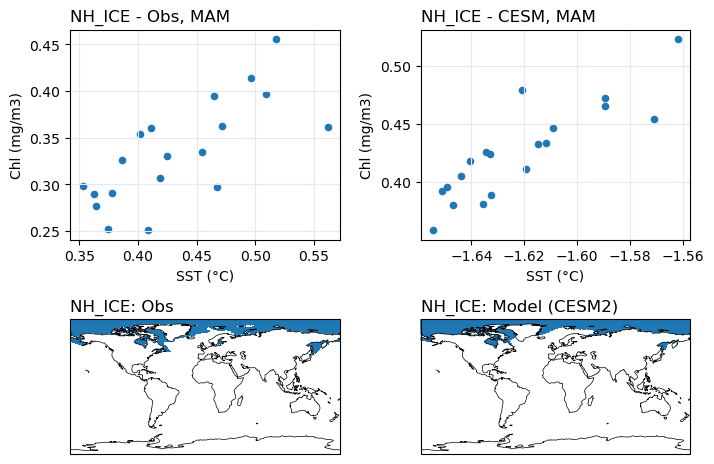

----------------------------------------------------------------------------------------------
2


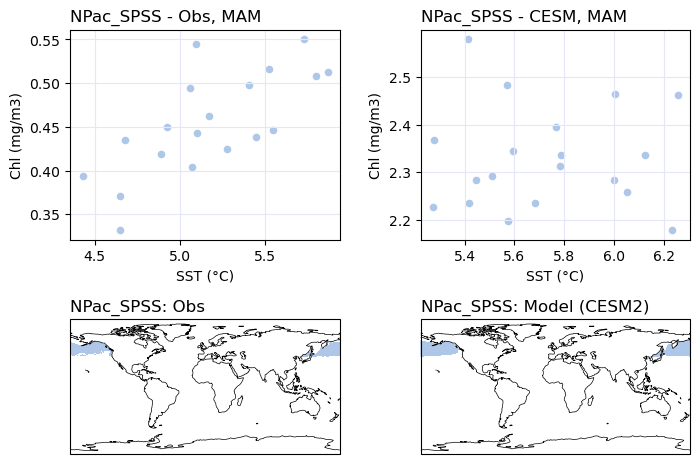

----------------------------------------------------------------------------------------------
3


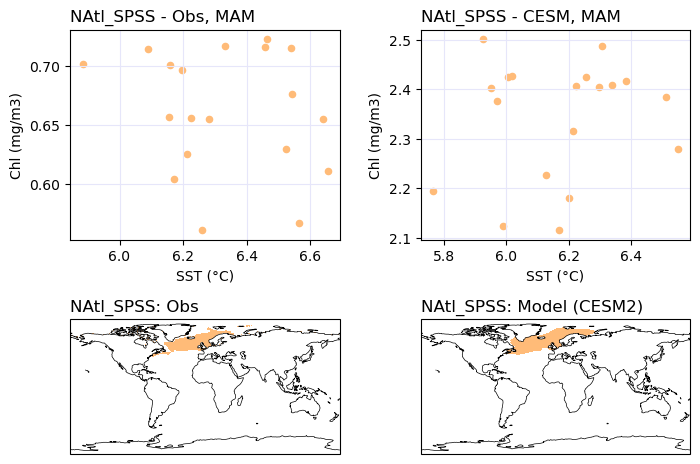

----------------------------------------------------------------------------------------------
4


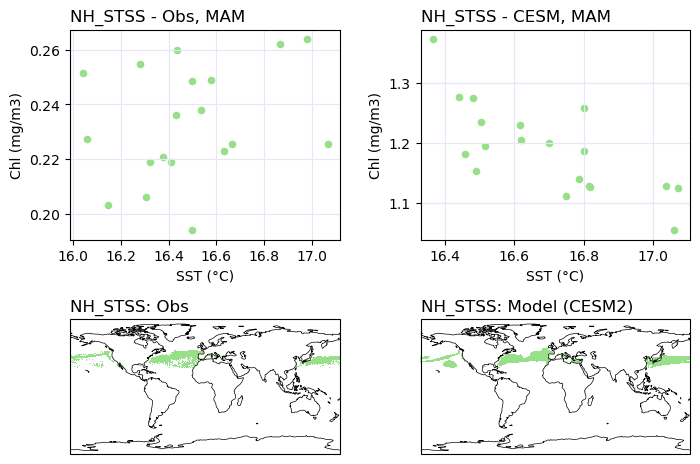

----------------------------------------------------------------------------------------------
5


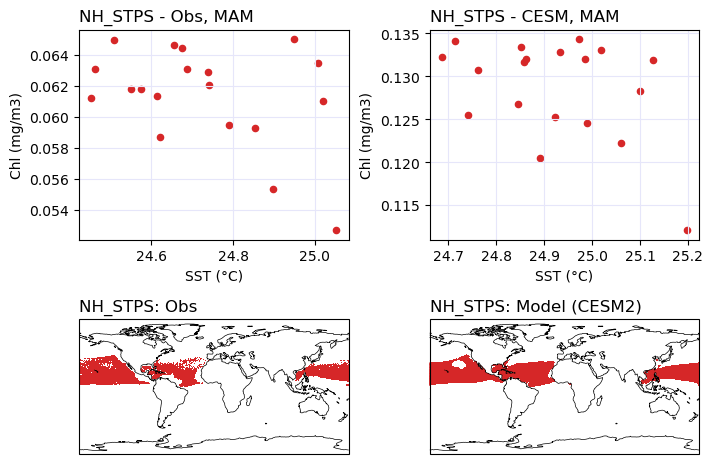

----------------------------------------------------------------------------------------------
6


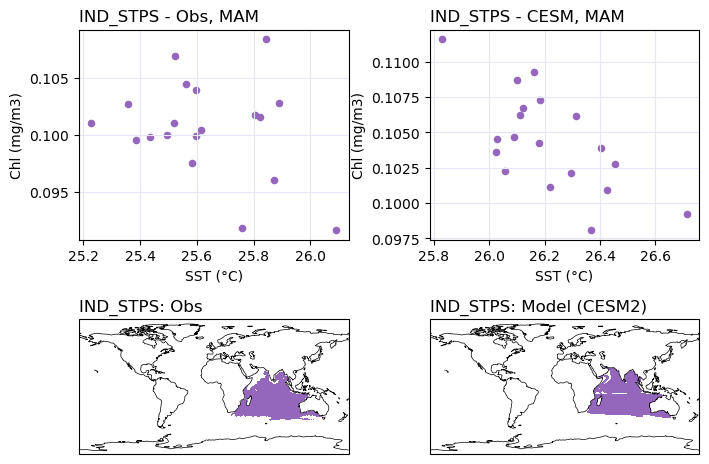

----------------------------------------------------------------------------------------------
7


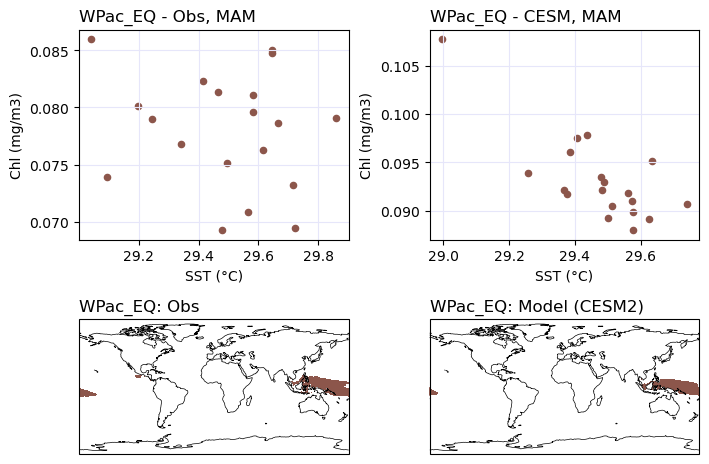

----------------------------------------------------------------------------------------------
8


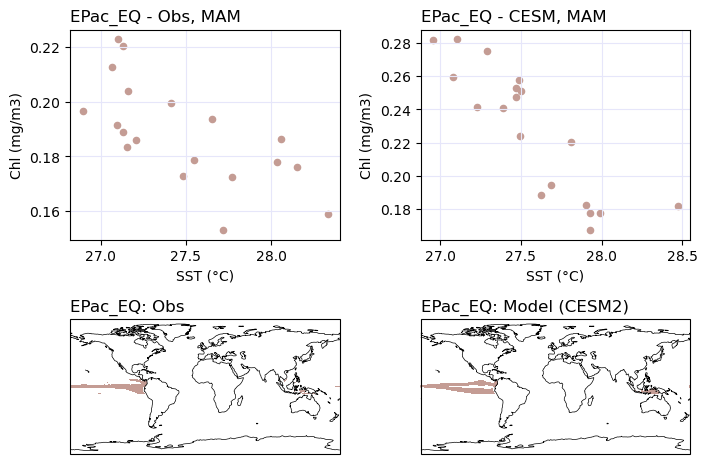

----------------------------------------------------------------------------------------------
9


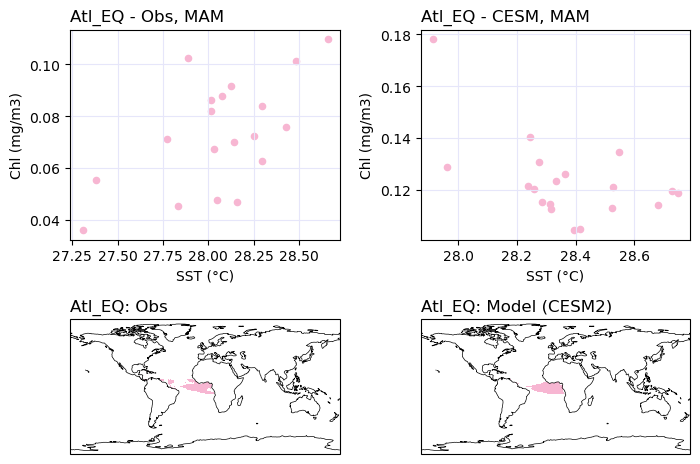

----------------------------------------------------------------------------------------------
10


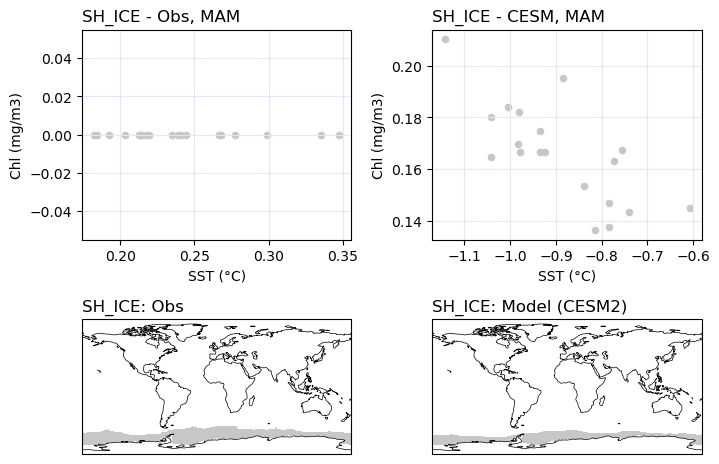

----------------------------------------------------------------------------------------------
11


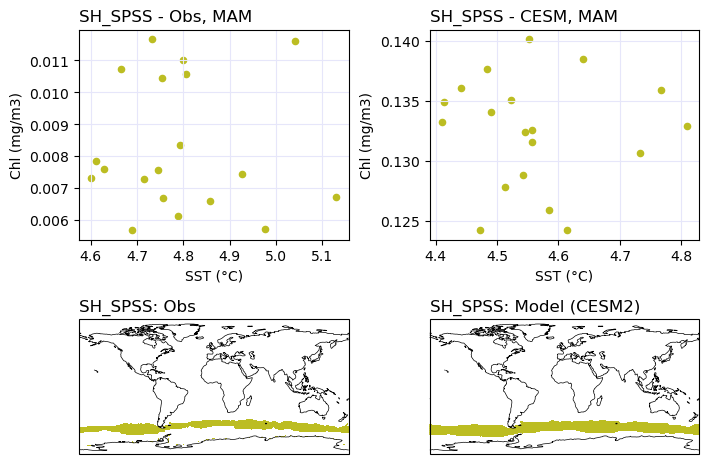

----------------------------------------------------------------------------------------------
12


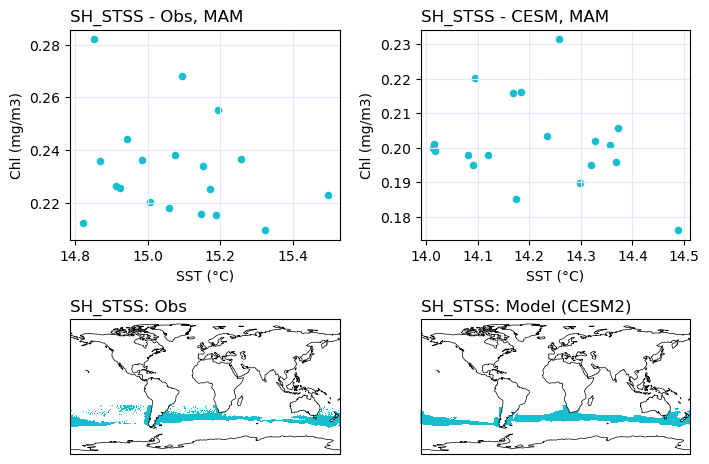

----------------------------------------------------------------------------------------------
13


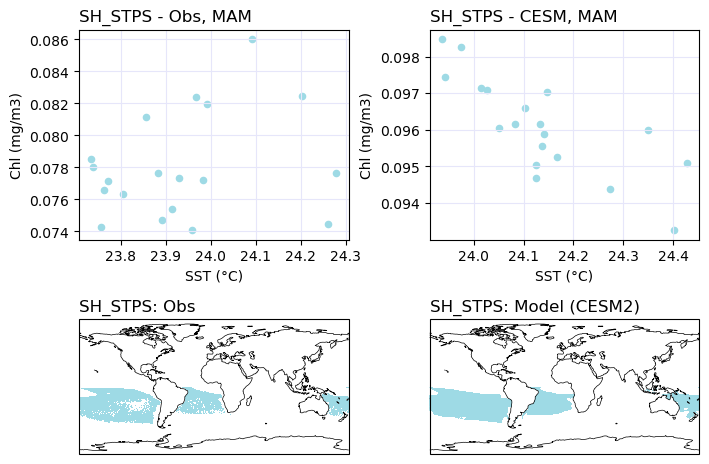

----------------------------------------------------------------------------------------------


In [33]:
for biome in biome_names:

    print(biome_num_dict[biome])
    fig = plt.figure(figsize=(8,6))

    ax = fig.add_subplot(2,2,1)
    ax.set_title(biome + ' - Obs, MAM', loc='left')
    xvals = obs_biome_dict_MAM[biome].SST
    yvals = obs_biome_dict_MAM[biome].Chl
    rgba_color = cmap_biome(biome_num_dict[biome]/14)
    sc = ax.scatter(xvals, yvals, color=rgba_color, s=20)
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender');
    ax.set_xlabel('SST (°C)')
    ax.set_ylabel('Chl (mg/m3)')
    #ax.set_ylim(0,3)
    
    ax = fig.add_subplot(2,2,2)
    ax.set_title(biome + ' - CESM, MAM', loc='left')
    xvals = model_biome_dict_MAM[biome].TEMP
    yvals = model_biome_dict_MAM[biome].Chl
    rgba_color = cmap_biome(biome_num_dict[biome]/14)
    sc = ax.scatter(xvals, yvals, color=rgba_color, s=20)
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender');
    ax.set_xlabel('SST (°C)')
    ax.set_ylabel('Chl (mg/m3)');
    #ax.set_ylim(0,3);


    ax = fig.add_subplot(2,2,3, projection=ccrs.PlateCarree())
    ax.coastlines('110m',linewidth=0.5)
    ax.set_title(biome + ': Obs', fontsize=12, loc='left')
    pc1=ax.pcolormesh(ds_biome_obs.lon, ds_biome_obs.lat, (ds_biome_obs.biome-0.5).where(ds_biome_obs.biome==biome_num_dict[biome]), cmap=cmap_biome,vmin=0,vmax=13,
                      transform=ccrs.PlateCarree())
    #pci=ax.contourf(lons, lats, all_biomes.where(all_biomes==0),levels=[0,0.99],transform=ccrs.PlateCarree(),hatches=['//'],colors='none')
    
    ax = fig.add_subplot(2,2,4, projection=ccrs.PlateCarree())
    ax.set_extent([-180,180,-90, 90], ccrs.PlateCarree())
    ax.coastlines('110m',linewidth=0.5)
    ax.set_title(biome + ': Model (CESM2)', fontsize=12, loc='left')
    pc1=ax.pcolormesh(lons, lats, (ds_biome_model.biome-0.5).where(ds_biome_model.biome==biome_num_dict[biome]), cmap=cmap_biome,vmin=0,vmax=13,
                      transform=ccrs.PlateCarree())
    
    fig.subplots_adjust(wspace=0.3)
    
    plt.show()
    print('----------------------------------------------------------------------------------------------')

### JJA SST vs. Chl (obs on left, model on right) for each biome

1


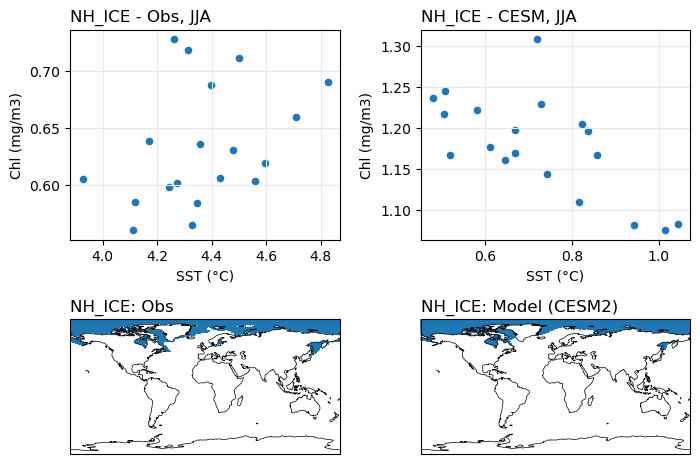

----------------------------------------------------------------------------------------------
2


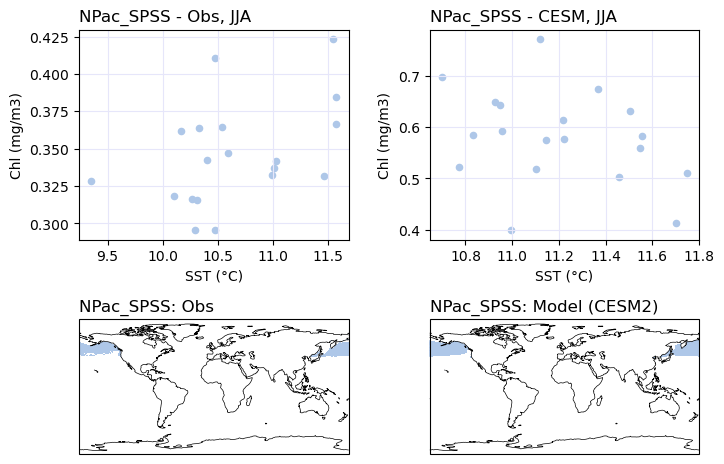

----------------------------------------------------------------------------------------------
3


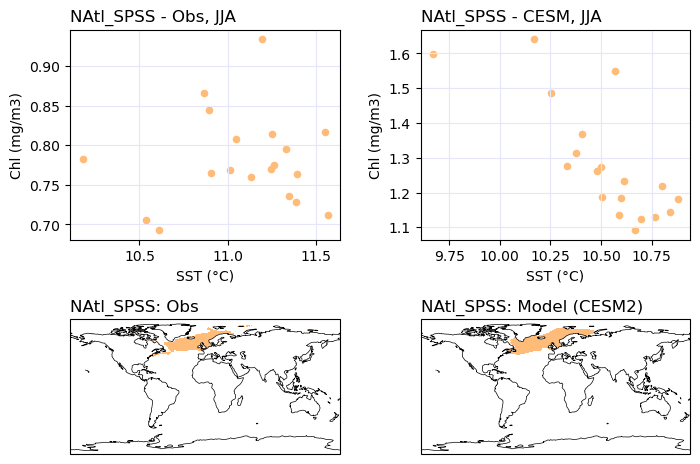

----------------------------------------------------------------------------------------------
4


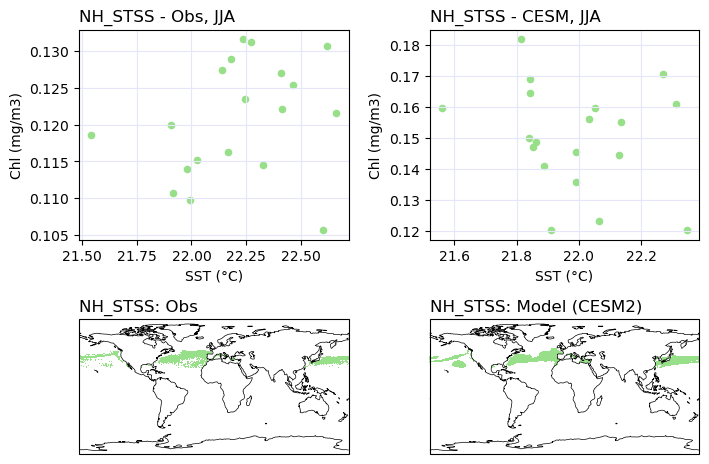

----------------------------------------------------------------------------------------------
5


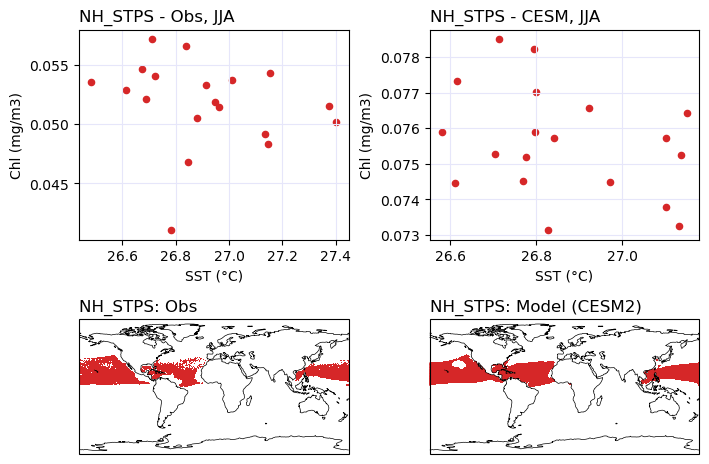

----------------------------------------------------------------------------------------------
6


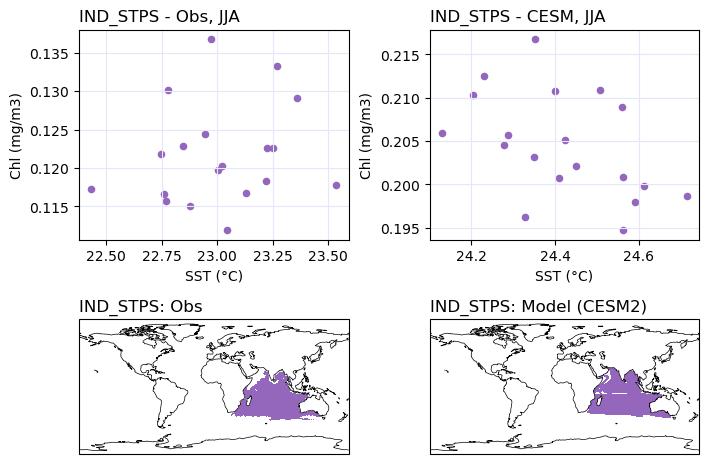

----------------------------------------------------------------------------------------------
7


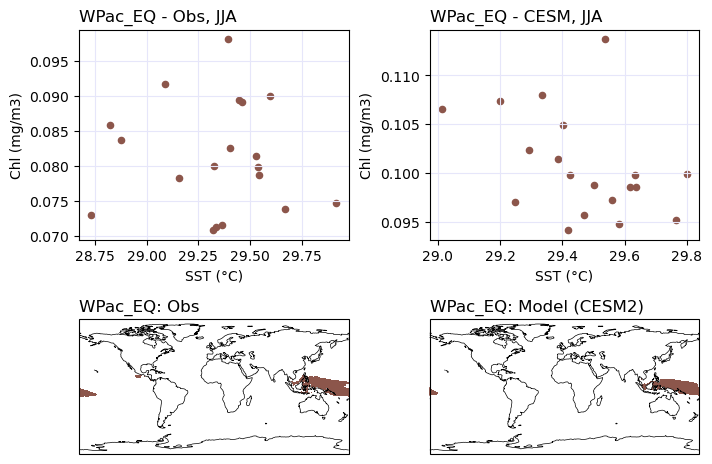

----------------------------------------------------------------------------------------------
8


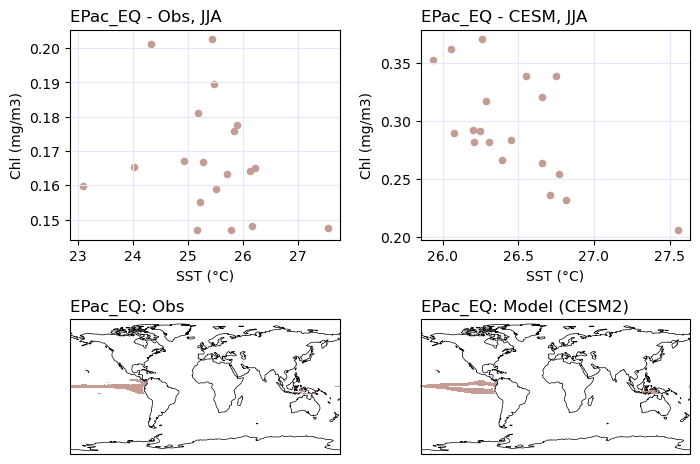

----------------------------------------------------------------------------------------------
9


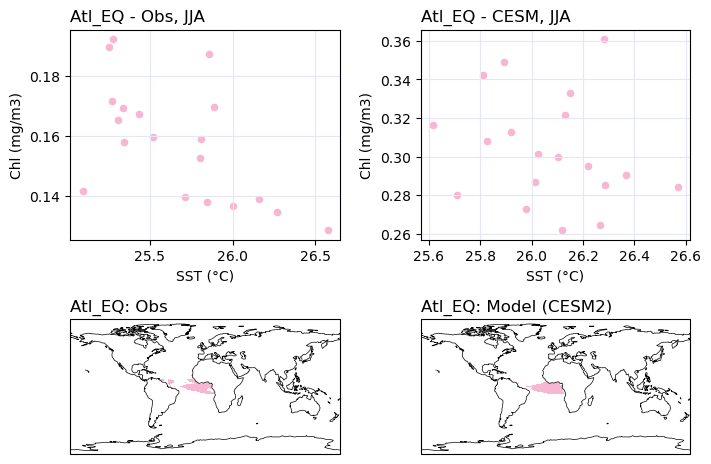

----------------------------------------------------------------------------------------------
10


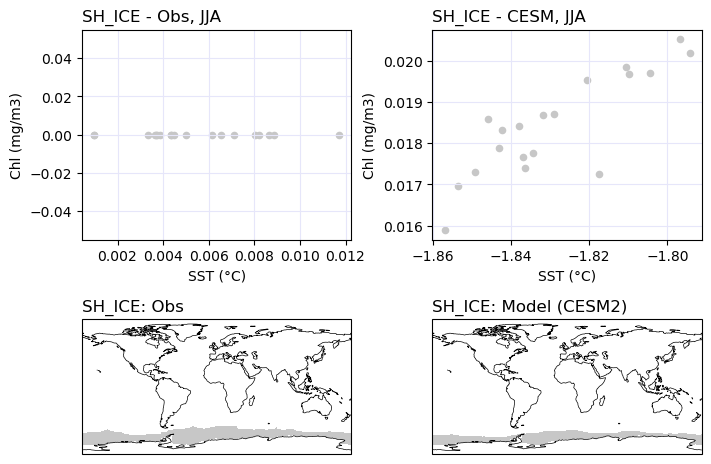

----------------------------------------------------------------------------------------------
11


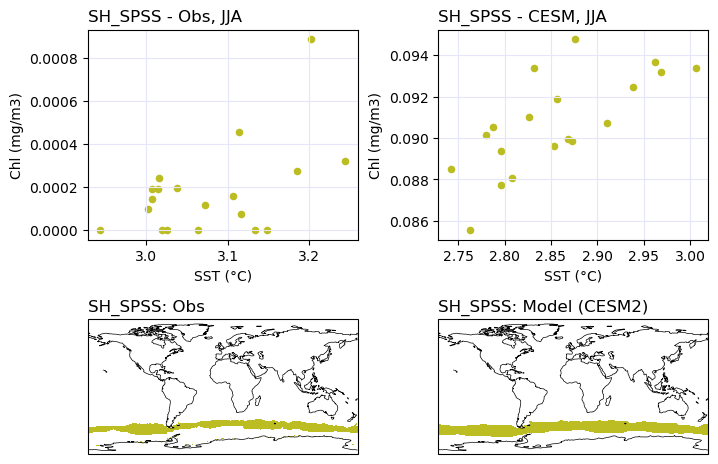

----------------------------------------------------------------------------------------------
12


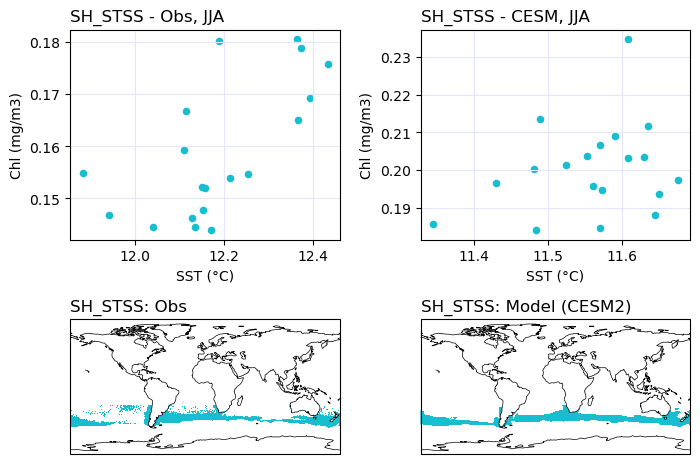

----------------------------------------------------------------------------------------------
13


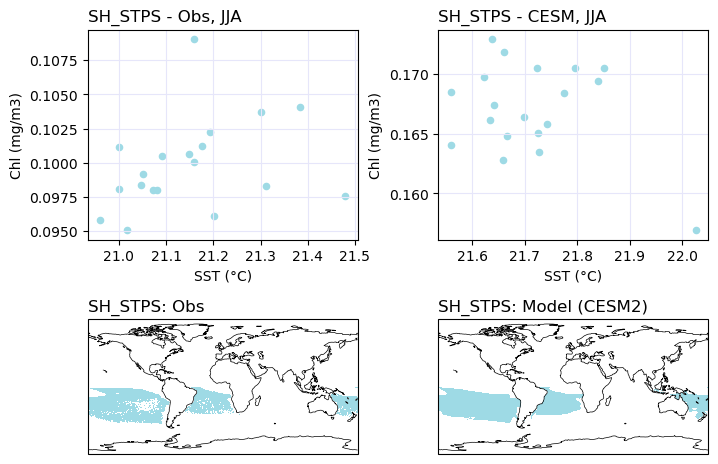

----------------------------------------------------------------------------------------------


In [31]:
for biome in biome_names:

    print(biome_num_dict[biome])
    fig = plt.figure(figsize=(8,6))

    ax = fig.add_subplot(2,2,1)
    ax.set_title(biome + ' - Obs, JJA', loc='left')
    xvals = obs_biome_dict_JJA[biome].SST
    yvals = obs_biome_dict_JJA[biome].Chl
    rgba_color = cmap_biome(biome_num_dict[biome]/14)
    sc = ax.scatter(xvals, yvals, color=rgba_color, s=20)
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender');
    ax.set_xlabel('SST (°C)')
    ax.set_ylabel('Chl (mg/m3)')
    #ax.set_ylim(0,3)
    
    ax = fig.add_subplot(2,2,2)
    ax.set_title(biome + ' - CESM, JJA', loc='left')
    xvals = model_biome_dict_JJA[biome].TEMP
    yvals = model_biome_dict_JJA[biome].Chl
    rgba_color = cmap_biome(biome_num_dict[biome]/14)
    sc = ax.scatter(xvals, yvals, color=rgba_color, s=20)
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender');
    ax.set_xlabel('SST (°C)')
    ax.set_ylabel('Chl (mg/m3)');
    #ax.set_ylim(0,3);


    ax = fig.add_subplot(2,2,3, projection=ccrs.PlateCarree())
    ax.coastlines('110m',linewidth=0.5)
    ax.set_title(biome + ': Obs', fontsize=12, loc='left')
    pc1=ax.pcolormesh(ds_biome_obs.lon, ds_biome_obs.lat, (ds_biome_obs.biome-0.5).where(ds_biome_obs.biome==biome_num_dict[biome]), cmap=cmap_biome,vmin=0,vmax=13,
                      transform=ccrs.PlateCarree())
    #pci=ax.contourf(lons, lats, all_biomes.where(all_biomes==0),levels=[0,0.99],transform=ccrs.PlateCarree(),hatches=['//'],colors='none')
    
    ax = fig.add_subplot(2,2,4, projection=ccrs.PlateCarree())
    ax.set_extent([-180,180,-90, 90], ccrs.PlateCarree())
    ax.coastlines('110m',linewidth=0.5)
    ax.set_title(biome + ': Model (CESM2)', fontsize=12, loc='left')
    pc1=ax.pcolormesh(lons, lats, (ds_biome_model.biome-0.5).where(ds_biome_model.biome==biome_num_dict[biome]), cmap=cmap_biome,vmin=0,vmax=13,
                      transform=ccrs.PlateCarree())
    
    fig.subplots_adjust(wspace=0.3)
    
    plt.show()
    print('----------------------------------------------------------------------------------------------')

### SON SST vs. Chl (obs on left, model on right) for each biome

1


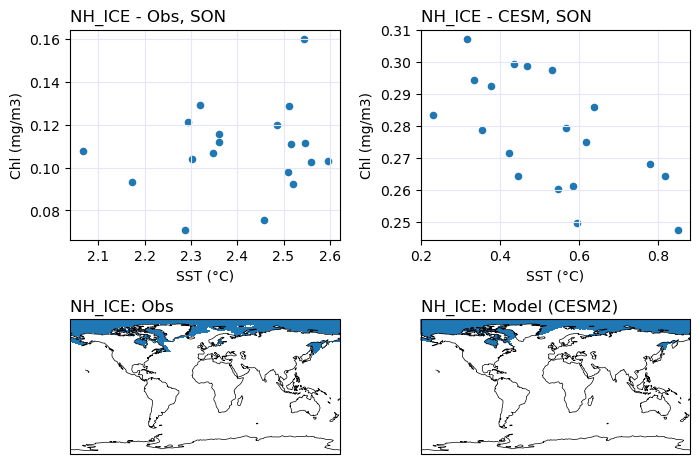

----------------------------------------------------------------------------------------------
2


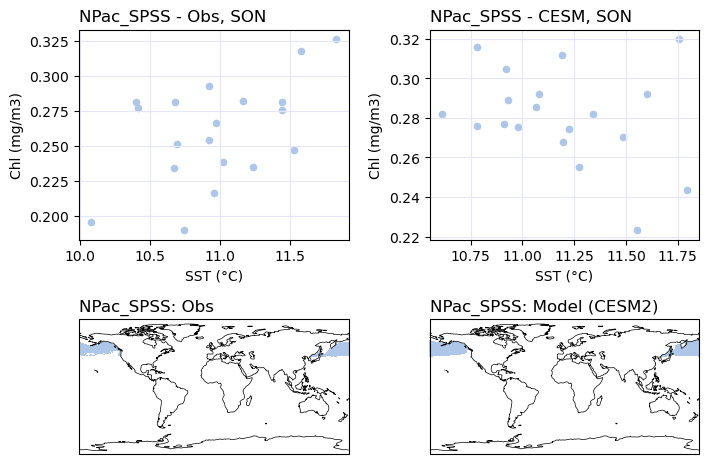

----------------------------------------------------------------------------------------------
3


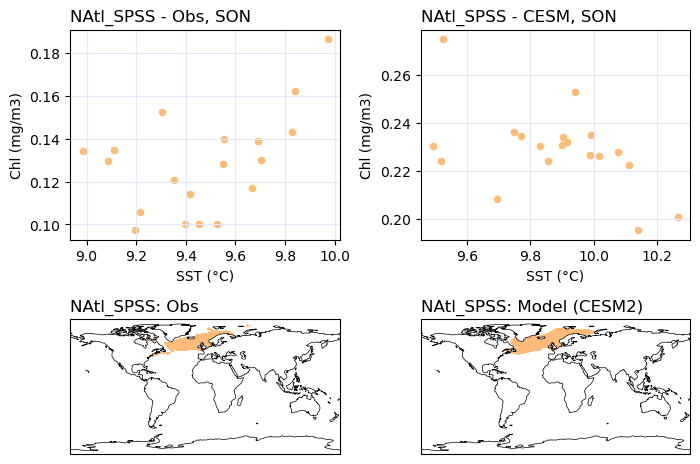

----------------------------------------------------------------------------------------------
4


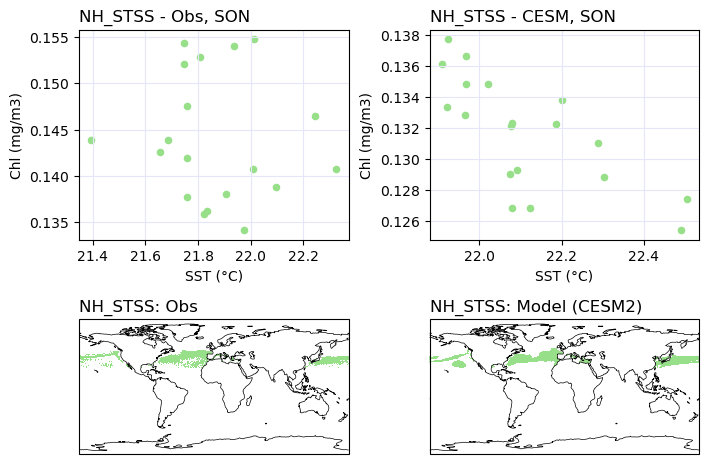

----------------------------------------------------------------------------------------------
5


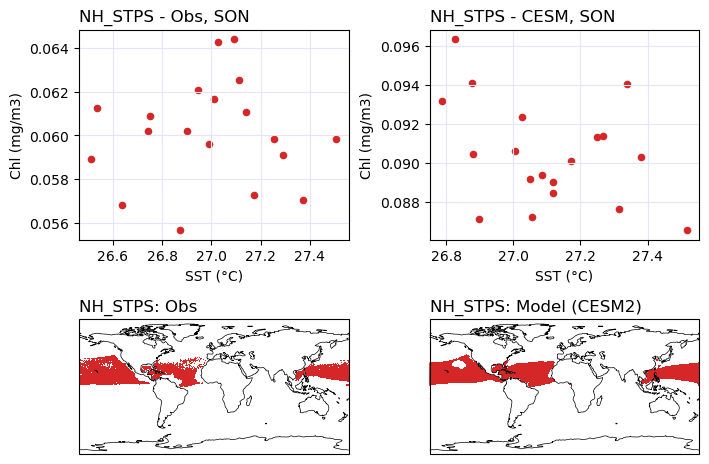

----------------------------------------------------------------------------------------------
6


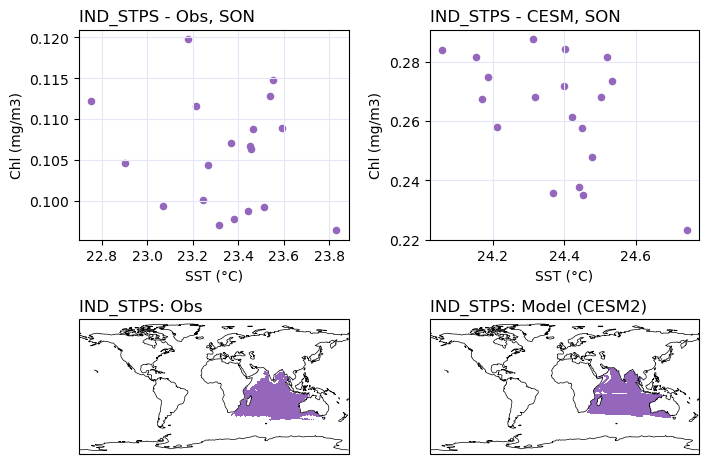

----------------------------------------------------------------------------------------------
7


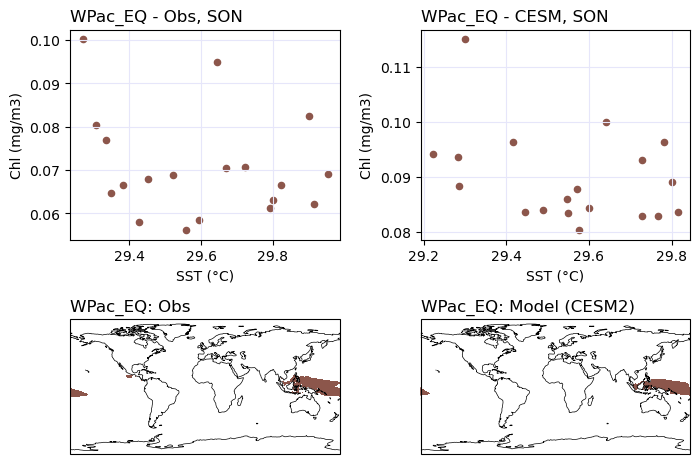

----------------------------------------------------------------------------------------------
8


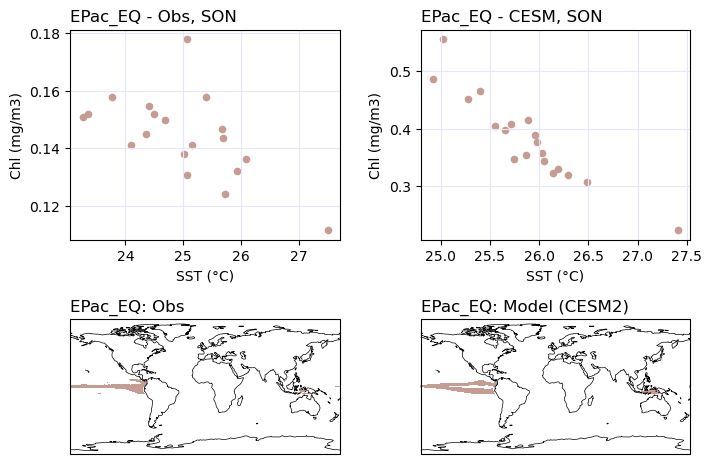

----------------------------------------------------------------------------------------------
9


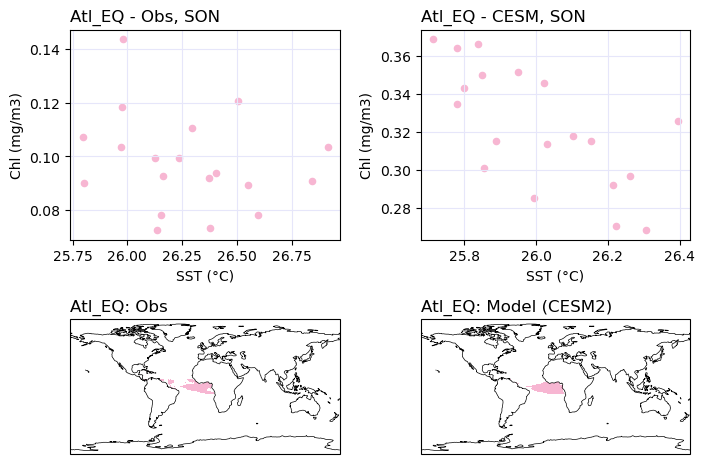

----------------------------------------------------------------------------------------------
10


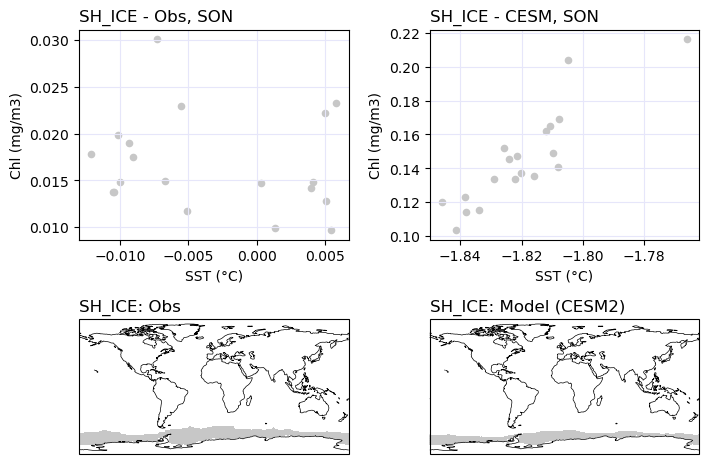

----------------------------------------------------------------------------------------------
11


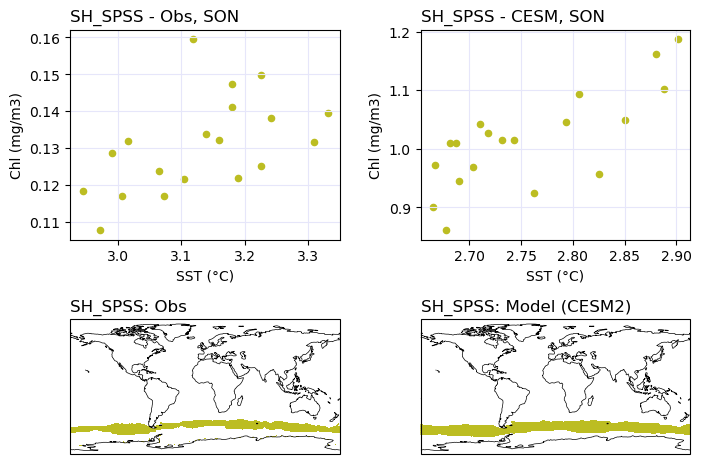

----------------------------------------------------------------------------------------------
12


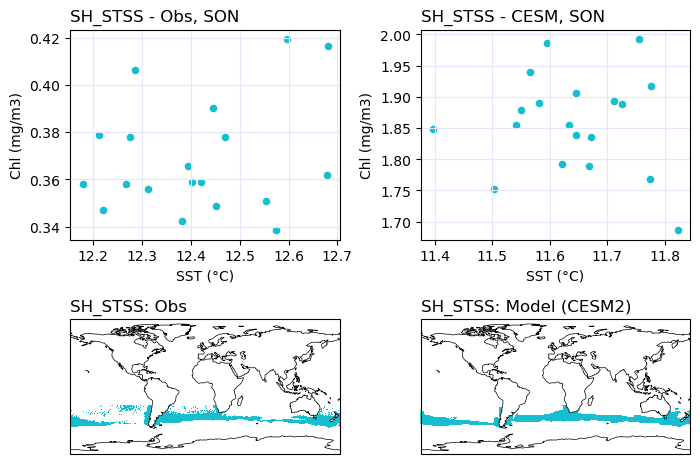

----------------------------------------------------------------------------------------------
13


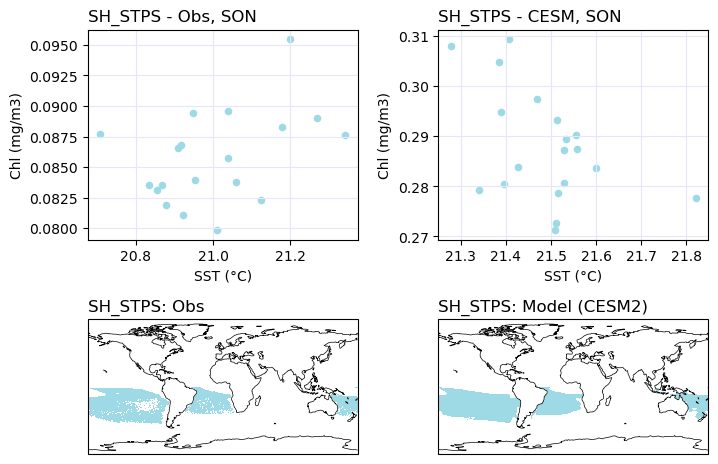

----------------------------------------------------------------------------------------------


In [32]:
for biome in biome_names:

    print(biome_num_dict[biome])
    fig = plt.figure(figsize=(8,6))

    ax = fig.add_subplot(2,2,1)
    ax.set_title(biome + ' - Obs, SON', loc='left')
    xvals = obs_biome_dict_SON[biome].SST
    yvals = obs_biome_dict_SON[biome].Chl
    rgba_color = cmap_biome(biome_num_dict[biome]/14)
    sc = ax.scatter(xvals, yvals, color=rgba_color, s=20)
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender');
    ax.set_xlabel('SST (°C)')
    ax.set_ylabel('Chl (mg/m3)')
    #ax.set_ylim(0,3)
    
    ax = fig.add_subplot(2,2,2)
    ax.set_title(biome + ' - CESM, SON', loc='left')
    xvals = model_biome_dict_SON[biome].TEMP
    yvals = model_biome_dict_SON[biome].Chl
    rgba_color = cmap_biome(biome_num_dict[biome]/14)
    sc = ax.scatter(xvals, yvals, color=rgba_color, s=20)
    ax.xaxis.grid(True, which='major',color='lavender')
    ax.yaxis.grid(True, which='major',color='lavender');
    ax.set_xlabel('SST (°C)')
    ax.set_ylabel('Chl (mg/m3)');
    #ax.set_ylim(0,3);


    ax = fig.add_subplot(2,2,3, projection=ccrs.PlateCarree())
    ax.coastlines('110m',linewidth=0.5)
    ax.set_title(biome + ': Obs', fontsize=12, loc='left')
    pc1=ax.pcolormesh(ds_biome_obs.lon, ds_biome_obs.lat, (ds_biome_obs.biome-0.5).where(ds_biome_obs.biome==biome_num_dict[biome]), cmap=cmap_biome,vmin=0,vmax=13,
                      transform=ccrs.PlateCarree())
    #pci=ax.contourf(lons, lats, all_biomes.where(all_biomes==0),levels=[0,0.99],transform=ccrs.PlateCarree(),hatches=['//'],colors='none')
    
    ax = fig.add_subplot(2,2,4, projection=ccrs.PlateCarree())
    ax.set_extent([-180,180,-90, 90], ccrs.PlateCarree())
    ax.coastlines('110m',linewidth=0.5)
    ax.set_title(biome + ': Model (CESM2)', fontsize=12, loc='left')
    pc1=ax.pcolormesh(lons, lats, (ds_biome_model.biome-0.5).where(ds_biome_model.biome==biome_num_dict[biome]), cmap=cmap_biome,vmin=0,vmax=13,
                      transform=ccrs.PlateCarree())
    
    fig.subplots_adjust(wspace=0.3)
    
    plt.show()
    print('----------------------------------------------------------------------------------------------')

### Combine biome maps into one figure

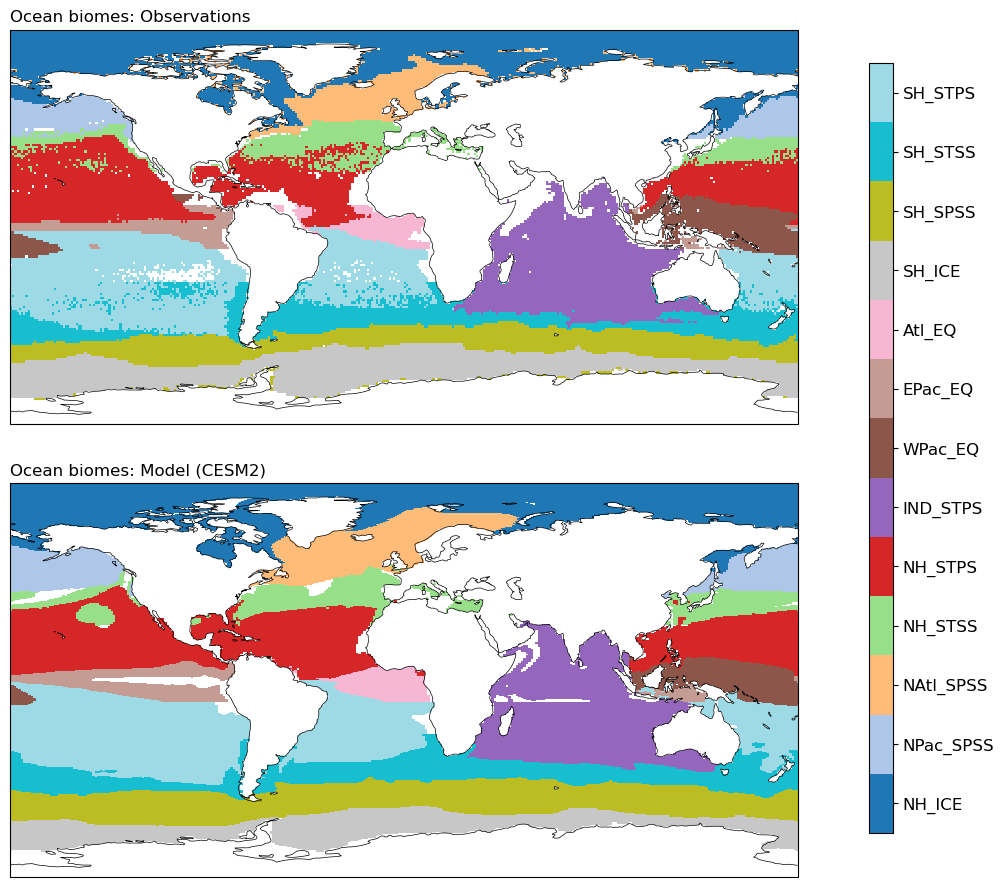

In [24]:
fig = plt.figure(figsize=(12,11))

ax = fig.add_subplot(2,1,1, projection=ccrs.PlateCarree())
ax.coastlines('110m',linewidth=0.5)
ax.set_title('Ocean biomes: Observations', fontsize=12, loc='left')
pc1=ax.pcolormesh(ds_biome_obs.lon, ds_biome_obs.lat, ds_biome_obs.biome-0.5, cmap=cmap_biome,vmin=0,vmax=13,
                  transform=ccrs.PlateCarree())
#pci=ax.contourf(lons, lats, all_biomes.where(all_biomes==0),levels=[0,0.99],transform=ccrs.PlateCarree(),hatches=['//'],colors='none')

ax = fig.add_subplot(2,1,2, projection=ccrs.PlateCarree())
ax.set_extent([-180,180,-90, 90], ccrs.PlateCarree())
ax.coastlines('110m',linewidth=0.5)
ax.set_title('Ocean biomes: Model (CESM2)', fontsize=12, loc='left')
pc1=ax.pcolormesh(lons, lats, ds_biome_model.biome-0.5, cmap=cmap_biome,vmin=0,vmax=13,
                  transform=ccrs.PlateCarree())
#pci=ax.contourf(lons, lats, all_biomes.where(all_biomes==0),levels=[0,0.99],transform=ccrs.PlateCarree(),hatches=['//'],colors='none')


fig.subplots_adjust(right=0.8, hspace=0.15)
cbar_ax = fig.add_axes([0.85, 0.15, 0.02, 0.7])
cbar1 = fig.colorbar(pc1, cax=cbar_ax, ticks=np.arange(0.5,13.5,1), pad=0.03)
cbar1.ax.set_yticklabels(biome_names, fontsize=12) ;
